# 04. Помогают ли дополнительные признаки

Сначала сравниваем каждую модель с её собственной версией на базовых полях. Потом смотрим качество разных семейств. Это отвечает на два разных вопроса: полезна ли подготовка признаков и какая модель лучше по выбранной метрике.

Строки обучения, валидации и теста общие. Внутри каждой пары одинаковы настройки и цель обучения; меняется только набор признаков. Между семействами цели обучения различаются: Ridge минимизирует квадраты ошибок, CatBoost — абсолютные ошибки, нейросети — квадраты ошибок логарифма количества. Поэтому разница между семействами отражает и модель, и её функцию потерь.

## Две версии одной модели

| Версия | Что видит модель |
|---|---|
| Базовые поля, 5 входов | Склад, артикул, два уровня категории и характеристика товара |
| С FE, 50 входов | Те же поля + календарь, история продаж, вчерашние остатки, общие продажи склада/товара и явные сочетания |

Внутри пары одинаковы обучающие строки, временные границы, функция потерь и правило выбора момента остановки. Меняется набор входов. FE — создание дополнительных признаков; все определения есть в [словаре](../features/FEATURES.md). Подготовка нулевых дней нужна обеим версиям и не считается различием между ними.

**Как читаем качество.** MAE — средняя абсолютная ошибка в штуках; меньше лучше. WAPE — суммарная абсолютная ошибка / суммарные продажи, в таблицах это доля. RMSE сильнее штрафует большие ошибки. RMSLE считает ошибку в логарифмической шкале. Смещение (bias) — средний прогноз минус факт; отрицательное значение означает недопрогноз. Валидация выбирает настройки, тест проверяет уже выбранную модель.

In [1]:
from pathlib import Path
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'docs/datasets').is_dir())

import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from features.catalog import LABELS, GROUP_LABELS, MODEL_LABELS, feature_label, identifier_label, display_ru
plt.rcParams.update({'date.autoformatter.month':'%m.%Y','date.autoformatter.day':'%d.%m',
                     'date.autoformatter.year':'%Y'})

RAW = ROOT / 'docs/datasets'
PROCESSED = ROOT / 'data/processed'
PROCESSED.mkdir(parents=True, exist_ok=True)
SEED = 42
pd.set_option('display.max_columns', 80)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


from sklearn.metrics import mean_absolute_error, mean_squared_error, mean_squared_log_error
OUT=ROOT/'data/artifacts/training'; MODELS=ROOT/'data/models'
OUT.mkdir(parents=True,exist_ok=True); MODELS.mkdir(parents=True,exist_ok=True)
manifest=json.loads((PROCESSED/'feature_manifest.json').read_text())
frames={s:pd.read_parquet(PROCESSED/f'{s}.parquet') for s in ['train','valid','test']}
FEATURE_SETS=manifest['feature_sets']
ALL_CATS=FEATURE_SETS['fe']['categorical']
for df in frames.values():
    for c in ALL_CATS: df[c]=df[c].astype('string').fillna('__MISSING__').astype(str)
assert frames['train'].date.max()<frames['valid'].date.min()<frames['test'].date.min()
assert set(FEATURE_SETS['base']['categorical'])<=set(ALL_CATS)

def metrics(y,pred):
    y=np.asarray(y,dtype='float64'); pred=np.maximum(np.asarray(pred,dtype='float64'),0)
    assert np.isfinite(pred).all() and len(y)==len(pred)
    return {'MAE':float(mean_absolute_error(y,pred)),
            'WAPE':float(np.abs(y-pred).sum()/y.sum()) if y.sum()>0 else np.nan,
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'RMSLE':float(np.sqrt(mean_squared_log_error(y,pred))),
            'bias':float(np.mean(pred-y))}

def save_result(name,predictions,seconds,family,setting,columns,params):
    records=[]; output=[]
    for split,pred in predictions.items():
        pred=np.maximum(np.asarray(pred),0)
        records.append({'model':name,'family':family,'feature_set':setting,'feature_count':len(columns),
                        'split':split,**metrics(frames[split].quantity,pred),'fit_seconds':float(seconds)})
        p=frames[split][['date','pair_id','quantity']].copy(); p['prediction']=pred; p['split']=split; output.append(p)
    result=pd.DataFrame(records)
    result.to_csv(OUT/f'{name}_metrics.csv',index=False)
    pd.concat(output,ignore_index=True).to_parquet(PROCESSED/f'{name}_predictions.parquet',index=False)
    contract={'model':name,'family':family,'feature_set':setting,'features':columns,'parameters':params,
              'seed':SEED,'train_rows':len(frames['train']),
              'train_end':manifest['train_end'],'valid_start':manifest['valid_start'],'test_start':manifest['test_start']}
    (OUT/f'{name}_experiment.json').write_text(json.dumps(contract,indent=2,ensure_ascii=False))
    display_ru(result.round(5))
    return result

def show_pair(family):
    rows=pd.concat([pd.read_csv(OUT/f'{family}_{s}_metrics.csv') for s in ['base','fe']])
    display_ru(rows[['model','feature_count','split','MAE','WAPE','RMSE','bias']].round(5))
    for split in ['valid','test']:
        p=rows[rows.split.eq(split)].set_index('feature_set')
        gain=100*(1-p.loc['fe','MAE']/p.loc['base','MAE'])
        display(Markdown(f"**{MODEL_LABELS[split]}:** MAE меняется с {p.loc['base','MAE']:.4f} до {p.loc['fe','MAE']:.4f}; улучшение {gain:+.1f}%. Плюс означает уменьшение ошибки."))
    return rows

def fit_plot(y,pred,title,filename):
    fig,axes=plt.subplots(1,2,figsize=(13,4))
    z=pd.DataFrame({'actual':np.asarray(y),'predicted':np.maximum(pred,0)})
    z['bin']=pd.cut(z.predicted,[-.001,.1,.25,.5,1,2,4,8,16,np.inf])
    calibration=z.groupby('bin',observed=True).agg(actual=('actual','mean'),predicted=('predicted','mean'))
    axes[0].plot(calibration.predicted,calibration.actual,'o-')
    mx=max(calibration.predicted.max(),calibration.actual.max()); axes[0].plot([0,mx],[0,mx],'--',alpha=.5)
    axes[0].set(xlabel='Средний прогноз',ylabel='Средний факт',title='Калибровка: совпадает ли прогноз с фактом')
    residual=z.predicted-z.actual
    axes[1].hist(residual.clip(residual.quantile(.01),residual.quantile(.99)),bins=60)
    axes[1].set(xlabel='Прогноз минус факт: центральные 98%',title=title)
    plt.tight_layout(); plt.savefig(OUT/filename,dpi=160,bbox_inches='tight'); plt.show()

display_ru(pd.DataFrame([{'split':s,'rows':len(f),'date_min':f.date.min().date(),'date_max':f.date.max().date()} for s,f in frames.items()]))
print('Протокол: прогноз на день по данным, известным по конец предыдущего дня.')

,Период,Число строк,Первая дата,Последняя дата
0,Обучение,600000,2024-01-29,2026-06-05
1,Валидация,245758,2026-06-06,2026-07-03
2,Тест,245784,2026-07-04,2026-07-31


Протокол: прогноз на день по данным, известным по конец предыдущего дня.


## Основная таблица: база против FE

В каждой строке одно семейство модели. Положительный процент означает уменьшение MAE после добавления признаков. Валидация показывает качество при выборе настроек, тест — результат уже зафиксированного сравнения. Улучшение по тесту описываем, но не используем для новой настройки.

In [2]:
FAMILIES=['linear','catboost','dcn']
REFERENCES=['zero','seasonal_lag7','rolling_mean7']
MODEL_NAMES=REFERENCES+[f'{f}_{s}' for f in FAMILIES+['mlp'] for s in ['base','fe']]
results=pd.concat([pd.read_csv(OUT/f'{name}_metrics.csv') for name in MODEL_NAMES],ignore_index=True)
results.to_csv(OUT/'all_metrics.csv',index=False)
paired=[]
for family in FAMILIES+['mlp']:
    r=results[results.family.eq(family)].set_index(['feature_set','split'])
    paired.append({'model':family,'base_valid_MAE':r.loc[('base','valid'),'MAE'],'fe_valid_MAE':r.loc[('fe','valid'),'MAE'],
                   'valid_gain_pct':100*(1-r.loc[('fe','valid'),'MAE']/r.loc[('base','valid'),'MAE']),
                   'base_test_MAE':r.loc[('base','test'),'MAE'],'fe_test_MAE':r.loc[('fe','test'),'MAE'],
                   'test_gain_pct':100*(1-r.loc[('fe','test'),'MAE']/r.loc[('base','test'),'MAE'])})
paired=pd.DataFrame(paired); paired.to_csv(OUT/'paired_comparison.csv',index=False)
display_ru(paired.round(5))
# Убеждаемся, что внутри пары отличаются только входы, а не настройки или строки.
for family in FAMILIES+['mlp']:
    base=json.loads((OUT/f'{family}_base_experiment.json').read_text())
    full=json.loads((OUT/f'{family}_fe_experiment.json').read_text())
    for key in ['parameters','seed','train_rows','train_end','valid_start','test_start']:
        assert base[key]==full[key],(family,key)
    assert base['features']==FEATURE_SETS['base']['categorical']
    assert set(base['features'])<set(full['features'])
print('В каждой паре одинаковы настройки и временная выборка; отличаются признаки.')
display_ru(results[results.split.eq('test')][['model','feature_count','MAE','WAPE','RMSE','bias']].round(5))

,Модель,MAE на валидации: база,MAE на валидации: FE,"Улучшение на валидации, %",MAE на тесте: база,MAE на тесте: FE,"Улучшение на тесте, %"
0,Линейная регрессия (Ridge),0.40687,0.34988,14.00743,0.42414,0.36349,14.29936
1,CatBoost,0.37550,0.27571,26.57514,0.39333,0.28647,27.16878
2,Нейросеть DCN,0.38124,0.32311,15.24881,0.39949,0.33563,15.98627
3,Нейросеть без cross-ветки,0.37225,0.32038,13.93489,0.39034,0.33286,14.72398


В каждой паре одинаковы настройки и временная выборка; отличаются признаки.


,Модель,Число признаков,"MAE, шт.","WAPE, доля","RMSE, шт.","Смещение, шт."
1,Всегда ноль,0,0.39972,1.00000,1.43842,-0.39972
3,Продажи 7 дней назад,1,0.41422,1.03628,1.16845,-0.00340
5,Среднее прошлых 7 дней,1,0.35717,0.89355,0.88182,0.00032
7,Ridge: базовые поля,5,0.42414,1.06109,1.19716,-0.12412
9,Ridge: с FE,50,0.36349,0.90936,0.84109,0.01800
11,CatBoost: базовые поля,5,0.39333,0.98402,1.39636,-0.37683
13,CatBoost: с FE,50,0.28647,0.71667,0.88596,-0.15993
15,DCN: базовые поля,5,0.39949,0.99942,1.19860,-0.23073
17,DCN: с FE,50,0.33563,0.83965,0.86926,-0.08675
19,MLP: базовые поля,5,0.39034,0.97652,1.17331,-0.22984


## Отдельно: какие группы и какая ветка полезны

У CatBoost каждую группу добавляем при одной функции потерь MAE. У нейросетей сравниваем MLP и DCN на одинаковом наборе. Обучаемые взаимодействия DCN и ручные cross-категории — разные способы использовать сочетания.

In [3]:
cat_ablation=pd.read_csv(OUT/'catboost_ablation.csv')
display_ru(cat_ablation[['variant','feature_count','MAE','MAE_change_vs_previous']].round(5))
cross_effect=[]
for setting in ['base','fe']:
    r=results[(results.feature_set.eq(setting))&results.split.eq('valid')].set_index('family')
    cross_effect.append({'feature_set':setting,'MLP MAE':r.loc['mlp','MAE'],'DCN MAE':r.loc['dcn','MAE'],
                         'Разница DCN − MLP':r.loc['dcn','MAE']-r.loc['mlp','MAE']})
display_ru(pd.DataFrame(cross_effect).round(5))
a=cat_ablation.set_index('variant')
display(Markdown(f"История и общие продажи меняют MAE с **{a.loc['calendar_identity','MAE']:.4f}** до **{a.loc['history_aggregate','MAE']:.4f}**. Остатки дают **{a.loc['history_stock','MAE']:.4f}**, явные сочетания — **{a.loc['full_crosses','MAE']:.4f}**. Основной прирост здесь связан с историей."))
r=results[(results.feature_set.eq('fe'))&results.split.eq('valid')].set_index('family')
display(Markdown(f"При одинаковых полных входах validation MAE MLP = **{r.loc['mlp','MAE']:.4f}**, DCN = **{r.loc['dcn','MAE']:.4f}**. Разница DCN минус MLP = **{r.loc['dcn','MAE']-r.loc['mlp','MAE']:+.4f}**; отрицательная означала бы преимущество cross-ветки. Это один seed."))


,Набор признаков,Число признаков,"MAE, шт.",Изменение MAE к предыдущему набору
0,Только исходные категории,5,0.37550,NaN
1,+ Календарь,18,0.37648,0.00098
2,+ История и агрегаты,38,0.27849,-0.09799
3,+ Остатки,47,0.27692,-0.00157
4,+ Явные сочетания,50,0.27571,-0.00121


,Набор входов,MLP MAE,DCN MAE,Разница DCN − MLP
0,Базовые поля,0.37225,0.38124,0.00899
1,С добавленными признаками,0.32038,0.32311,0.00273


История и общие продажи меняют MAE с **0.3765** до **0.2785**. Остатки дают **0.2769**, явные сочетания — **0.2757**. Основной прирост здесь связан с историей.

При одинаковых полных входах validation MAE MLP = **0.3204**, DCN = **0.3231**. Разница DCN минус MLP = **+0.0027**; отрицательная означала бы преимущество cross-ветки. Это один seed.

## Нули, положительные продажи и новые пары

При большом числе нулей маленький общий MAE может сочетаться с недопрогнозом общего объёма. Поэтому отдельно считаем ошибку на днях с продажами, новых парах и пропущенных остатках. Калибровка сравнивает средний факт со средним прогнозом в группах похожих прогнозов.

Модель,CatBoost: базовые поля,CatBoost: с FE,DCN: базовые поля,DCN: с FE,Ridge: базовые поля,Ridge: с FE
Срез,,,,,,
Все дни,0.39333,0.28647,0.39949,0.33563,0.42414,0.36349
Пары моложе 28 дней,0.00000,0.00000,0.01786,0.02688,0.00000,0.01309
Дни с продажами,2.12504,1.38089,1.74489,1.29964,1.54345,1.16473
Нет вчерашнего остатка,0.01621,0.01622,0.03783,0.03457,0.02284,0.03390
Дни без продаж,0.00897,0.04356,0.10087,0.12166,0.17570,0.18565


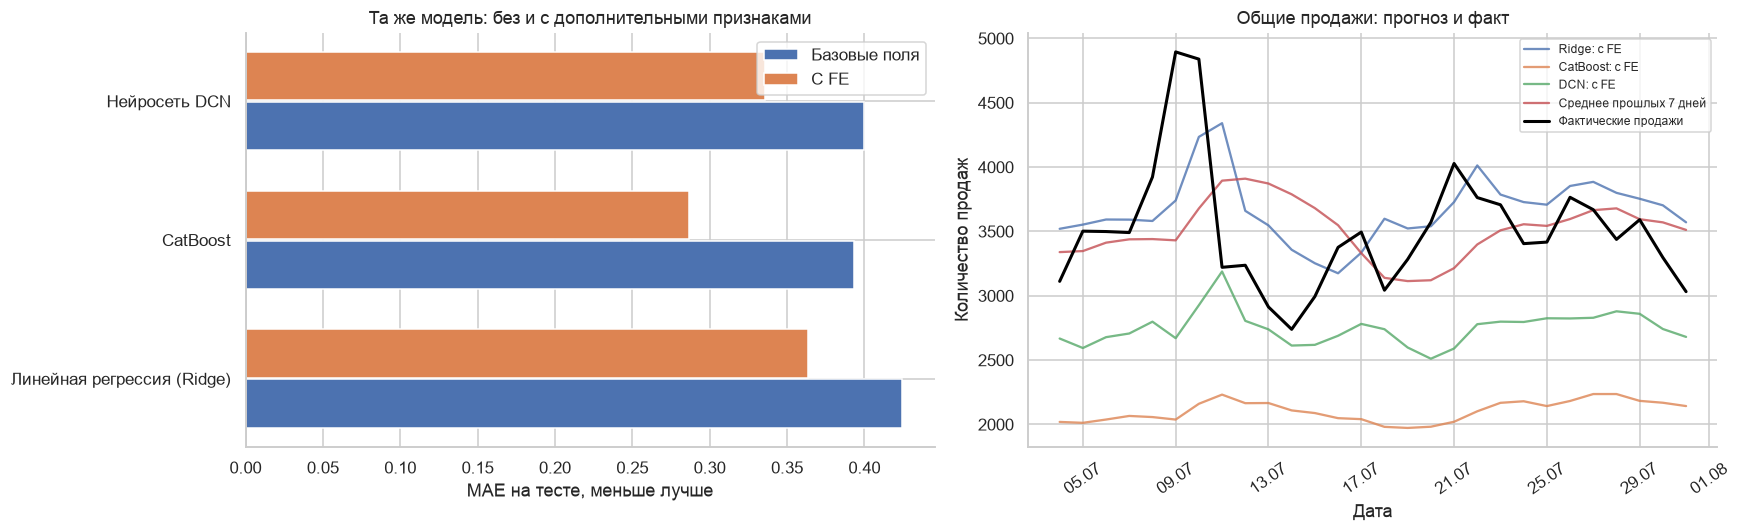

In [4]:
errors=[]; daily=[]; warehouse=[]; test=frames['test']
segments={'all':np.ones(len(test),dtype=bool),'zero_sales':test.quantity.eq(0).to_numpy(),
          'positive_sales':test.quantity.gt(0).to_numpy(),'pair_age_lt28':test.pair_age_days.lt(28).to_numpy(),
          'stock_missing':test.stock_missing_lag_1.eq(1).to_numpy()}
for name in MODEL_NAMES:
    p=pd.read_parquet(PROCESSED/f'{name}_predictions.parquet')
    p=p[p.split.eq('test')].reset_index(drop=True)
    assert p[['date','pair_id']].equals(test[['date','pair_id']])
    np.testing.assert_array_equal(p.quantity.to_numpy(),test.quantity.to_numpy())
    for segment,mask in segments.items():
        if mask.any():errors.append({'model':name,'segment':segment,'rows':int(mask.sum()),**metrics(test.quantity.to_numpy()[mask],p.prediction.to_numpy()[mask])})
    p['warehouse_name']=test.warehouse_name.to_numpy()
    for wh,g in p.groupby('warehouse_name'):
        warehouse.append({'model':name,'warehouse_name':wh,'rows':len(g),**metrics(g.quantity,g.prediction)})
    d=p.groupby('date')[['quantity','prediction']].sum(); d['model']=name; daily.append(d.reset_index())
segments_df=pd.DataFrame(errors); segments_df.to_csv(OUT/'error_segments.csv',index=False)
pd.DataFrame(warehouse).to_csv(OUT/'warehouse_metrics.csv',index=False)
daily_df=pd.concat(daily,ignore_index=True); daily_df.to_csv(OUT/'daily_predictions.csv',index=False)
main_names=[f'{f}_{s}' for f in FAMILIES for s in ['base','fe']]
display_ru(segments_df[segments_df.model.isin(main_names)].pivot(index='segment',columns='model',values='MAE').round(5))
fig,axes=plt.subplots(1,2,figsize=(16,5))
pairs=paired[paired.model.isin(FAMILIES)].set_index('model').loc[FAMILIES]
y=np.arange(len(pairs))
axes[0].barh(y-.18,pairs.base_test_MAE,height=.35,label='Базовые поля')
axes[0].barh(y+.18,pairs.fe_test_MAE,height=.35,label='С FE')
axes[0].set(yticks=y,yticklabels=[MODEL_LABELS[f] for f in FAMILIES],xlabel='MAE на тесте, меньше лучше',title='Та же модель: без и с дополнительными признаками'); axes[0].legend()
for name in ['linear_fe','catboost_fe','dcn_fe','rolling_mean7']:
    g=daily_df[daily_df.model.eq(name)]; axes[1].plot(g.date,g.prediction,label=MODEL_LABELS[name],alpha=.8)
g=daily_df[daily_df.model.eq('zero')]; axes[1].plot(g.date,g.quantity,color='black',lw=2,label='Фактические продажи')
axes[1].set(title='Общие продажи: прогноз и факт',ylabel='Количество продаж',xlabel='Дата'); axes[1].tick_params(axis='x',rotation=35); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT/'07_model_comparison.png',dpi=160,bbox_inches='tight'); plt.show()

## Короткий вывод по выполненному прогону

Текст ниже собирается из сохранённых чисел. Результат относится к одной временной разбивке и однодневному прогнозу по обновляемой фактической истории. Официальная метрика ещё не предоставлена. Для прогноза нескольких недель от одной даты потребуется другая схема истории.

In [5]:
valid=results[results.split.eq('valid')].set_index('model')
test_scores=results[results.split.eq('test')].set_index('model')
candidates=[f'{f}_{s}' for f in FAMILIES for s in ['base','fe']]
best_name=valid.loc[candidates].MAE.idxmin(); best=test_scores.loc[best_name]
under=-best.bias/frames['test'].quantity.mean()
summary=f"Выбор среди основных моделей по MAE валидации: **{MODEL_LABELS[best_name]}**. На тесте MAE = **{best.MAE:.4f}**, WAPE = **{best.WAPE:.1%}**. Отклонение суммарного объёма: **{-under:+.1%}** относительно факта."
display(Markdown(summary)); (OUT/'run_summary.md').write_text(summary+'\n')
lines=['# Результаты сравнения базовых полей и FE','',summary,'',
       'В каждой паре использованы одни и те же 600 тыс. строк обучения и полные одинаковые периоды валидации и теста. Функция потерь и настройки внутри пары одинаковы. База — пять исходных категорий, FE — 50 входов.','',
       '| Модель | MAE теста: база | MAE теста: FE | Улучшение, % |','|---|---:|---:|---:|']
for _,r in paired.iterrows():
    lines.append(f"| {MODEL_LABELS[r.model]} | {r.base_test_MAE:.4f} | {r.fe_test_MAE:.4f} | {r.test_gain_pct:+.1f} |")
lines+=['','Снижение MAE не гарантирует точность суммарного объёма. CatBoost обучен на MAE, поэтому при частых нулях тяготеет к медиане; нейросети обучены в логарифмической шкале. RMSE и смещение приведены в итоговом ноутбуке. Между семействами отличаются и архитектура, и цель обучения.',
        '', 'Тест: 2026-07-04 — 2026-07-31. Прогнозы обновляются каждый день по фактически известной истории. Официальные цель, горизонт и метрика ещё не предоставлены.',
        '', 'Вклад групп признаков: `data/artifacts/training/catboost_ablation.csv`. Вклад cross-ветки: MLP против DCN на одинаковых входах в `03_dcn.ipynb`. Небольшие различия одного seed не считаем доказательством устойчивого эффекта.',
        '', 'Первую итерацию после перестройки можно повторить командой `python scripts/run_notebooks.py`.']
a=cat_ablation.set_index('variant')
r=results[(results.feature_set.eq('fe'))&results.split.eq('valid')].set_index('family')
lines += ['', f"История и общие продажи снижают validation MAE CatBoost с {a.loc['calendar_identity','MAE']:.4f} до {a.loc['history_aggregate','MAE']:.4f}. Остатки дают {a.loc['history_stock','MAE']:.4f}, явные сочетания — {a.loc['full_crosses','MAE']:.4f}. Основной прирост в этом порядке добавления связан с историей.",
          '', f"При одинаковых полных входах validation MAE MLP = {r.loc['mlp','MAE']:.4f}, DCN = {r.loc['dcn','MAE']:.4f}. Разница DCN минус MLP = {r.loc['dcn','MAE']-r.loc['mlp','MAE']:+.4f}; отрицательная означала бы преимущество cross-ветки. Это результат одного seed."]
(ROOT/'training/results.md').write_text('\n'.join(lines)+'\n')
import sys,platform,importlib.metadata
versions={n:importlib.metadata.version(n) for n in ['pandas','numpy','matplotlib','seaborn','pyarrow','scikit-learn','catboost','torch','nbformat','nbclient']}
(OUT/'environment.json').write_text(json.dumps({'python':sys.version,'platform':platform.platform(),'versions':versions,'seed':SEED},indent=2))

Выбор среди основных моделей по MAE валидации: **CatBoost: с FE**. На тесте MAE = **0.2865**, WAPE = **71.7%**. Отклонение суммарного объёма: **-40.0%** относительно факта.

432